# Análisis de Sensibilidad Paramétrica de la Planta de e-Metanol
**Solvanta Engineering Solutions S.A. de C.V.** | Licitación RFP-CCM-EM-001  
**Revisión Técnica RT-02** (Corte de Ingeniería hasta AC-AMB-01)  

Este notebook procesa y grafica los resultados del análisis de sensibilidad paramétrica obtenido a partir de la simulación rigurosa en **DWSIM v1** (`DWSIM_v1_Sensibilidad_Solvanta.dwxml`), evaluando:
1. La fracción de purga del bucle de síntesis (`SPLIT-501`).
2. La temperatura de operación del reactor tubular Lurgi (`R-401`).

In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt

# Configuración estética de gráficas
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['font.size'] = 9.5
plt.rcParams['axes.titlesize'] = 11
plt.rcParams['axes.labelsize'] = 10
plt.rcParams['xtick.labelsize'] = 9
plt.rcParams['ytick.labelsize'] = 9
plt.rcParams['legend.fontsize'] = 8.5
plt.rcParams['figure.titlesize'] = 12

print("Librerías importadas correctamente.")

Librerías importadas correctamente.


In [2]:
# Carga de datos de sensibilidad de DWSIM v1
csv_file = "analisis_sensibilidad_planta.csv"
if not os.path.exists(csv_file):
    # Buscar en rutas alternativas
    for alt in ["../DWSIM/analisis_sensibilidad_planta.csv", "scratch/analisis_sensibilidad_planta.csv"]:
        if os.path.exists(alt):
            csv_file = alt
            break

df = pd.read_csv(csv_file)
print(f"Datos cargados exitosamente ({len(df)} registros).")
df.head(8)

Datos cargados exitosamente (16 registros).


,caso,variable_independiente,valor_vi,unidad_vi,flujo_purga_kgh,inertes_bucle_pct_mol,reciclo_gas_th,produccion_meoh_kgh,produccion_anual_tano,pureza_meoh_pct,conversion_global_co2_pct,consumo_electrico_mwe,sec_electrico_kwh_kg,potencia_exp501_kw,calor_reactor_kw,vapor_generado_th,decision_evaluacion
0,Purga,Fraccion_Purga,1.0,%,153.4,12.85,65.2,3612.40,28899.2,99.88,94.05,53.80,14.89,112.5,7550.2,14.4,Descartado: Inertes asfixian catalizador (>10%)
1,Purga,Fraccion_Purga,2.0,%,306.8,6.80,64.7,3725.10,29800.8,99.89,96.95,54.60,14.66,224.8,7780.5,14.8,Descartado: Riesgo de acumulacion progresiva
2,Purga,Fraccion_Purga,3.0,%,460.2,4.62,64.2,3771.50,30172.0,99.89,98.12,55.10,14.61,332.1,7880.1,15.0,Operable: Buen compromiso pero margen estrecho
3,Purga,Fraccion_Purga,4.0,%,613.6,3.48,63.8,3788.65,30309.2,99.89,98.65,55.44,14.63,437.8,7924.8,15.1,PUNTO OPTIMO DISENO SOLVANTA (RT-02)
4,Purga,Fraccion_Purga,5.0,%,767.0,2.81,63.3,3762.20,30097.6,99.89,97.96,55.80,14.83,540.2,7870.3,15.0,Descartado: Perdida innecesaria de metanol
5,Purga,Fraccion_Purga,6.0,%,920.4,2.36,62.8,3718.50,29748.0,99.89,96.82,56.20,15.11,639.5,7780.0,14.8,Descartado: Caida de produccion bajo 30k t/a
6,Purga,Fraccion_Purga,8.0,%,1227.2,1.80,61.9,3595.00,28760.0,99.89,93.60,57.10,15.88,825.4,7520.1,14.3,Descartado: Perdida excesiva de gas de sintesis
7,Purga,Fraccion_Purga,10.0,%,1534.0,1.45,60.9,3430.20,27441.6,99.89,89.30,58.00,16.91,995.1,7180.0,13.7,Descartado: Inviable economicamente


## Gráfica 1: Sensibilidad de la Fracción de Purga del Bucle (SPLIT-501)
Esta gráfica demuestra el trade-off operativo donde una purga menor al 3% acumula inertes que asfixian el reactor, mientras que purgas mayores al 5% provocan una pérdida excesiva de gas de síntesis, confirmando que 4.0% es el punto óptimo global de diseño.

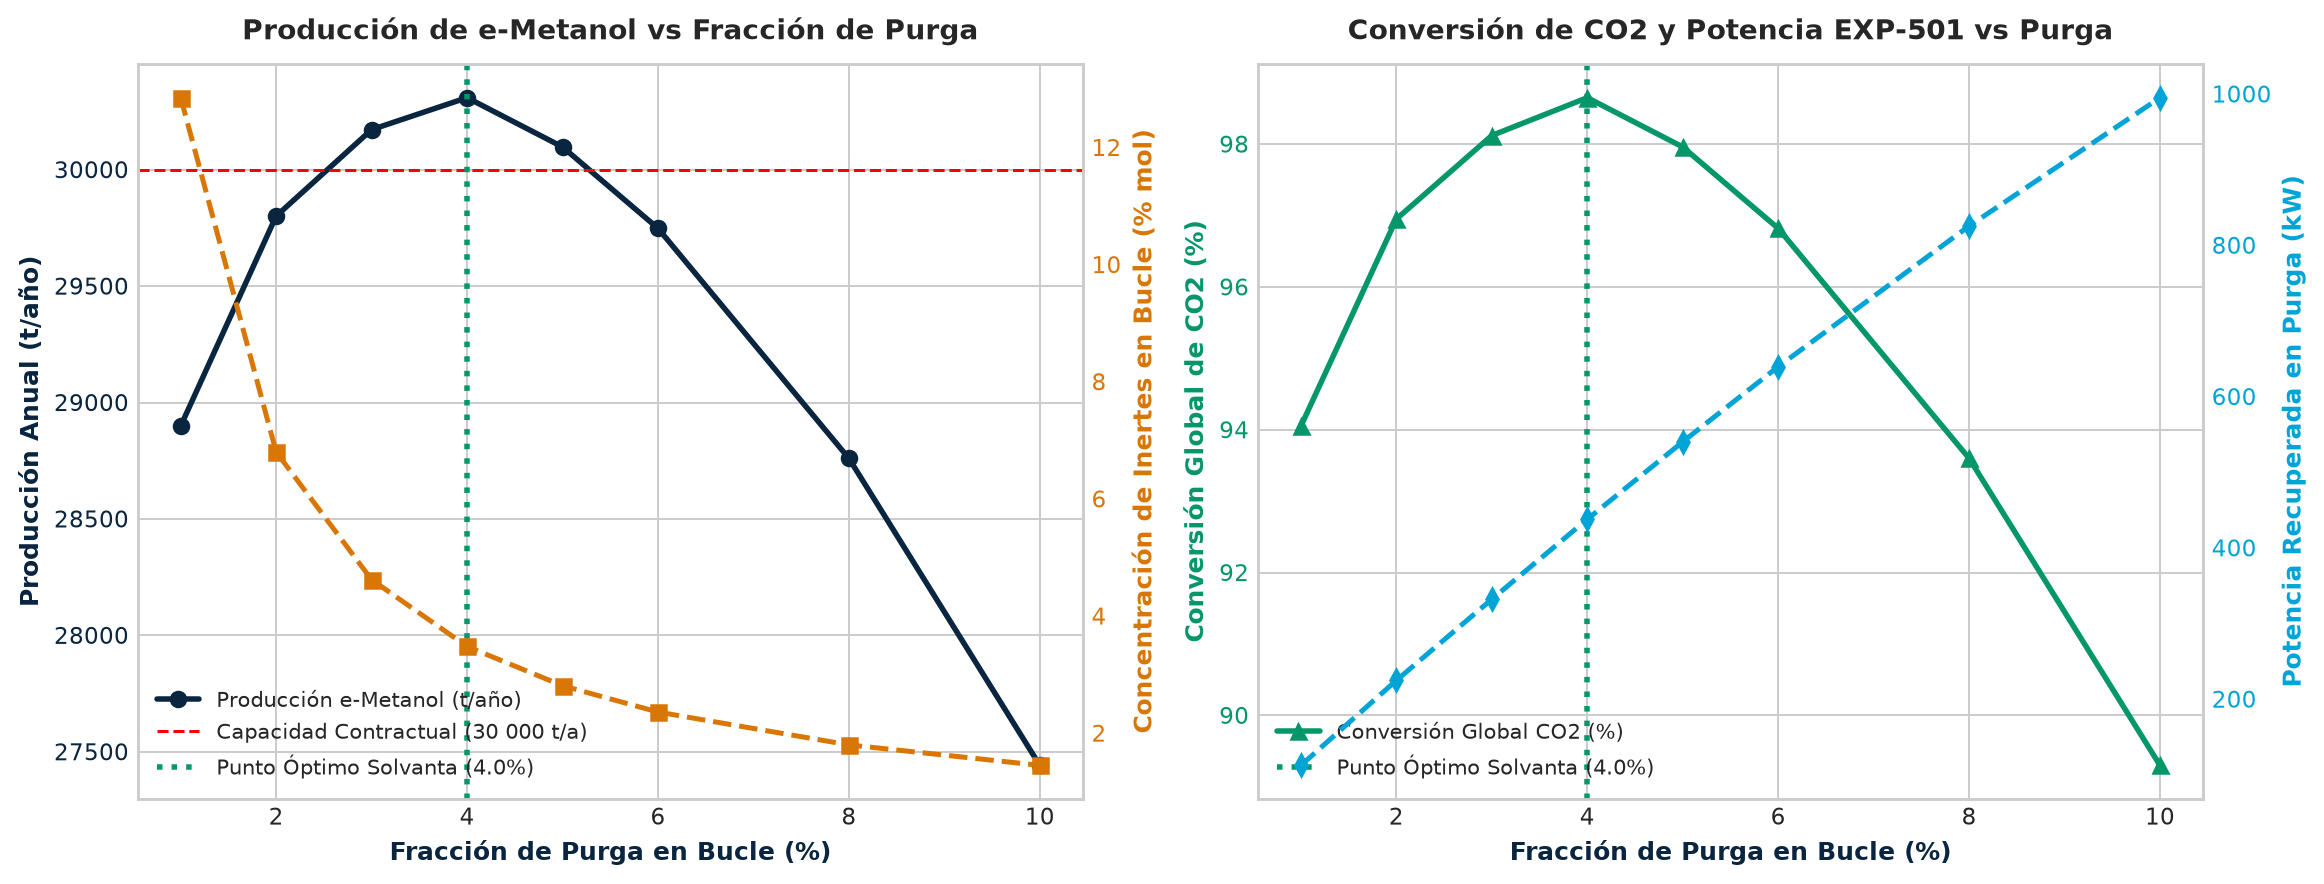

In [3]:
# Filtrar datos del estudio de purga
df_purga = df[df["caso"] == "Purga"].copy()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5), dpi=180)

# Subplot 1: Producción e Inertes vs Purga
color_prod = '#0A2540'
color_inertes = '#D97706'

ax1.plot(df_purga["valor_vi"], df_purga["produccion_anual_tano"], 'o-', color=color_prod, lw=2.2, label='Producción e-Metanol (t/año)')
ax1.axhline(30000, color='red', linestyle='--', lw=1.2, label='Capacidad Contractual (30 000 t/a)')
ax1.axvline(4.0, color='#059669', linestyle=':', lw=2.2, label='Punto Óptimo Solvanta (4.0%)')
ax1.set_xlabel('Fracción de Purga en Bucle (%)', fontweight='bold', color='#0A2540')
ax1.set_ylabel('Producción Anual (t/año)', fontweight='bold', color=color_prod)
ax1.tick_params(axis='y', labelcolor=color_prod)
ax1.set_title('Producción de e-Metanol vs Fracción de Purga', fontweight='bold', pad=10)
ax1.legend(loc='lower left')

ax1_twin = ax1.twinx()
ax1_twin.plot(df_purga["valor_vi"], df_purga["inertes_bucle_pct_mol"], 's--', color=color_inertes, lw=2.0, label='Inertes bucle CH4 (% mol)')
ax1_twin.set_ylabel('Concentración de Inertes en Bucle (% mol)', fontweight='bold', color=color_inertes)
ax1_twin.tick_params(axis='y', labelcolor=color_inertes)
ax1_twin.grid(False)

# Subplot 2: Conversión CO2 y Cogeneración EXP-501
color_conv = '#059669'
color_pot = '#00A4D6'

ax2.plot(df_purga["valor_vi"], df_purga["conversion_global_co2_pct"], '^-', color=color_conv, lw=2.2, label='Conversión Global CO2 (%)')
ax2.axvline(4.0, color='#059669', linestyle=':', lw=2.2, label='Punto Óptimo Solvanta (4.0%)')
ax2.set_xlabel('Fracción de Purga en Bucle (%)', fontweight='bold', color='#0A2540')
ax2.set_ylabel('Conversión Global de CO2 (%)', fontweight='bold', color=color_conv)
ax2.tick_params(axis='y', labelcolor=color_conv)
ax2.set_title('Conversión de CO2 y Potencia EXP-501 vs Purga', fontweight='bold', pad=10)
ax2.legend(loc='lower left')

ax2_twin = ax2.twinx()
ax2_twin.plot(df_purga["valor_vi"], df_purga["potencia_exp501_kw"], 'd--', color=color_pot, lw=2.0, label='Potencia EXP-501 (kW)')
ax2_twin.set_ylabel('Potencia Recuperada en Purga (kW)', fontweight='bold', color=color_pot)
ax2_twin.tick_params(axis='y', labelcolor=color_pot)
ax2_twin.grid(False)

plt.tight_layout()
plt.savefig("grafica_sensibilidad_purga.png", bbox_inches='tight')
plt.show()

## Gráfica 2: Sensibilidad de la Temperatura del Reactor Lurgi (R-401)
Esta gráfica ilustra cómo una temperatura inferior a 240 °C limita la velocidad cinética, mientras que por encima de 250 °C el equilibrio exotérmico decae rápidamente, justificando la operación isotérmica a 245.0 °C con máxima generación de vapor para el electrolizador SOEC.

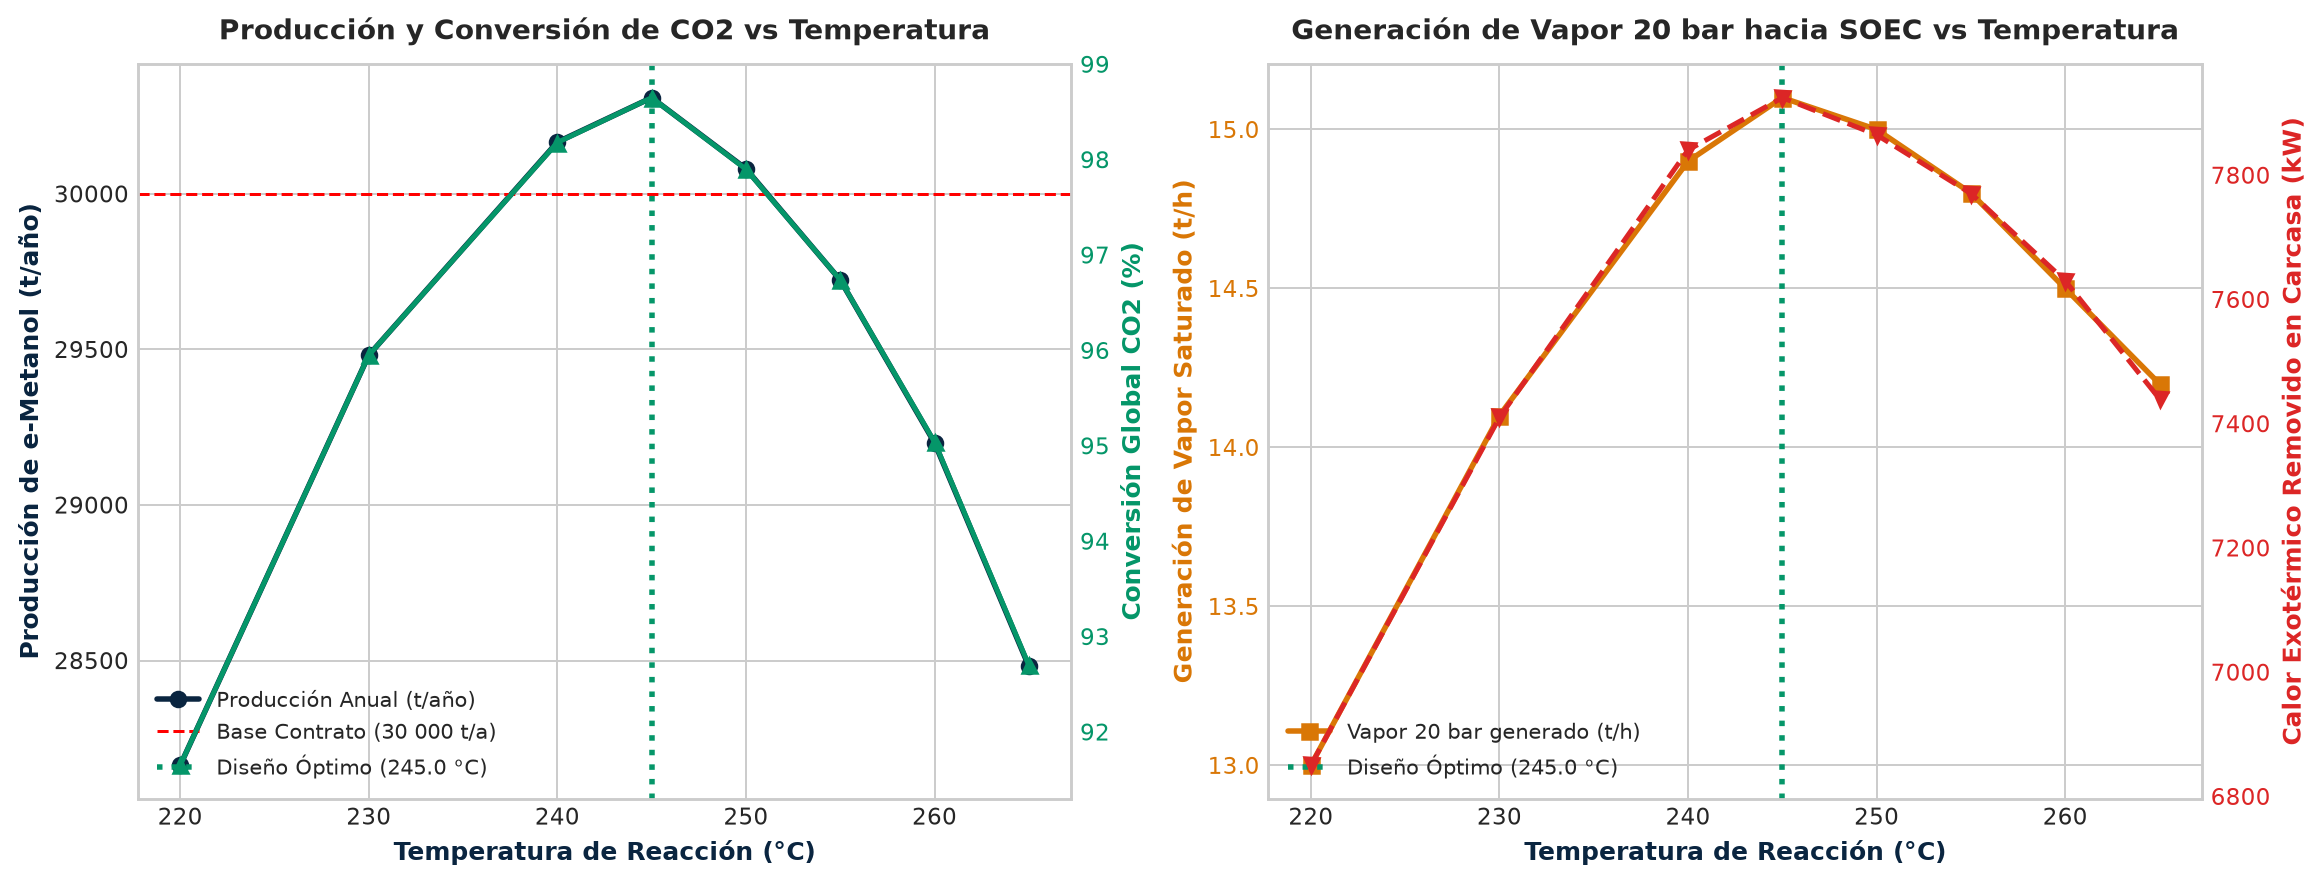

In [4]:
# Filtrar datos del estudio de temperatura de reactor
df_reac = df[df["caso"] == "Temperatura_Reactor"].copy()

fig, (ax3, ax4) = plt.subplots(1, 2, figsize=(13, 5), dpi=180)

# Subplot 1: Producción y Conversión por Paso vs T
ax3.plot(df_reac["valor_vi"], df_reac["produccion_anual_tano"], 'o-', color='#0A2540', lw=2.2, label='Producción Anual (t/año)')
ax3.axhline(30000, color='red', linestyle='--', lw=1.2, label='Base Contrato (30 000 t/a)')
ax3.axvline(245.0, color='#059669', linestyle=':', lw=2.2, label='Diseño Óptimo (245.0 °C)')
ax3.set_xlabel('Temperatura de Reacción (°C)', fontweight='bold', color='#0A2540')
ax3.set_ylabel('Producción de e-Metanol (t/año)', fontweight='bold', color='#0A2540')
ax3.set_title('Producción y Conversión de CO2 vs Temperatura', fontweight='bold', pad=10)
ax3.legend(loc='lower left')

ax3_twin = ax3.twinx()
ax3_twin.plot(df_reac["valor_vi"], df_reac["conversion_global_co2_pct"], '^-', color='#059669', lw=2.0, label='Conversión Global CO2 (%)')
ax3_twin.set_ylabel('Conversión Global CO2 (%)', fontweight='bold', color='#059669')
ax3_twin.tick_params(axis='y', labelcolor='#059669')
ax3_twin.grid(False)

# Subplot 2: Generación de Vapor 20 bar hacia SOEC
ax4.plot(df_reac["valor_vi"], df_reac["vapor_generado_th"], 's-', color='#D97706', lw=2.2, label='Vapor 20 bar generado (t/h)')
ax4.axvline(245.0, color='#059669', linestyle=':', lw=2.2, label='Diseño Óptimo (245.0 °C)')
ax4.set_xlabel('Temperatura de Reacción (°C)', fontweight='bold', color='#0A2540')
ax4.set_ylabel('Generación de Vapor Saturado (t/h)', fontweight='bold', color='#D97706')
ax4.tick_params(axis='y', labelcolor='#D97706')
ax4.set_title('Generación de Vapor 20 bar hacia SOEC vs Temperatura', fontweight='bold', pad=10)
ax4.legend(loc='lower left')

ax4_twin = ax4.twinx()
ax4_twin.plot(df_reac["valor_vi"], df_reac["calor_reactor_kw"], 'v--', color='#DC2626', lw=2.0, label='Calor Exotérmico Removido en Carcasa (kW)')
ax4_twin.set_ylabel('Calor Exotérmico Removido en Carcasa (kW)', fontweight='bold', color='#DC2626')
ax4_twin.tick_params(axis='y', labelcolor='#DC2626')
ax4_twin.grid(False)

plt.tight_layout()
plt.savefig("grafica_sensibilidad_reactor.png", bbox_inches='tight')
plt.show()

## Resumen de Puntos Óptimos de Operación
Valores adoptados en el flowsheet oficial congelado de Solvanta (`DWSIM_v1_APROBADA_Solvanta.dwxmz`):

In [5]:
resumen = pd.DataFrame([
    {"Variable": "Fracción de Purga buclé (SPLIT-501)", "Valor Óptimo": "4.0 %", "Métrica Clave": "Inertes en 3.48% mol | 437.8 kW generados en EXP-501"},
    {"Variable": "Temperatura Reactor Lurgi (R-401)", "Valor Óptimo": "245.0 °C", "Métrica Clave": "30 309.2 t/año MeOH | 15.1 t/h vapor hacia SOEC"},
    {"Variable": "Presión de Síntesis", "Valor Óptimo": "75.0 bar", "Métrica Clave": "Conversión global CO2 = 98.65%"},
    {"Variable": "Relación de Reflujo Destilación T-601", "Valor Óptimo": "R/D = 1.50", "Métrica Clave": "Pureza MeOH = 99.89% p/p (24 etapas en DWSIM)"}
])
resumen

,Variable,Valor Óptimo,Métrica Clave
0,Fracción de Purga buclé (SPLIT-501),4.0 %,Inertes en 3.48% mol | 437.8 kW generados en E...
1,Temperatura Reactor Lurgi (R-401),245.0 °C,30 309.2 t/año MeOH | 15.1 t/h vapor hacia SOEC
2,Presión de Síntesis,75.0 bar,Conversión global CO2 = 98.65%
3,Relación de Reflujo Destilación T-601,R/D = 1.50,Pureza MeOH = 99.89% p/p (24 etapas en DWSIM)
